Dataset loaded successfully!
Shape: (345327, 32)
Encoded categorical columns: ['state', 'district', 'crop', 'season']
Number of extreme rows: 70892
Data split into train and test sets.
Training model...

Train Evaluation:
R² Score : 0.9712
RMSE     : 155.0521
MAE      : 9.6783

Test Evaluation:
R² Score : 0.9532
RMSE     : 200.3113
MAE      : 12.1241

Extreme Test Set Evaluation:
R² Score : 0.9518
RMSE     : 442.0936
MAE      : 58.4541


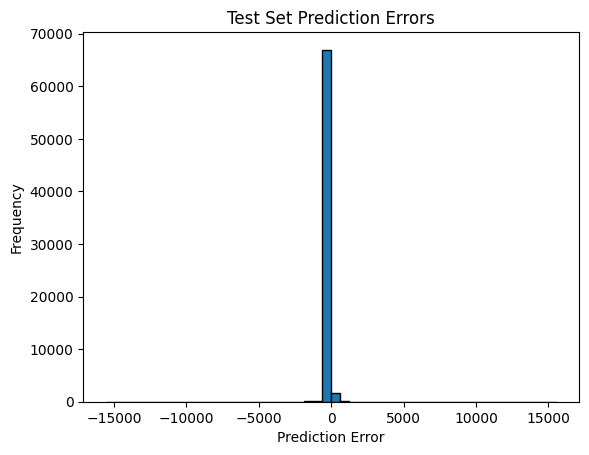

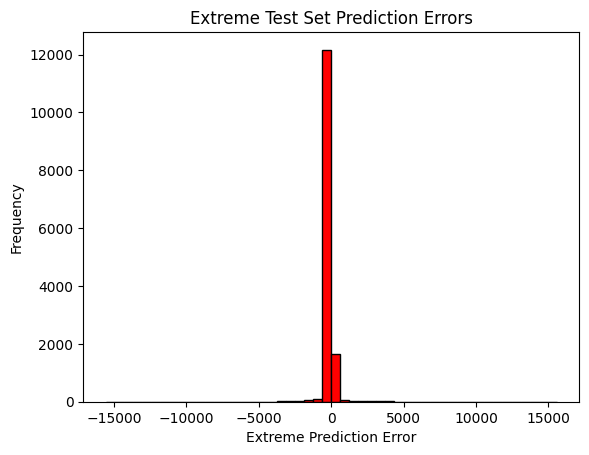


Model and encoders saved successfully!


In [ ]:
# crop_yield_train_balanced.py
import pandas as pd
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# =======================
# 1. Load dataset
# =======================
file_path = r"C:\Users\anjal\OneDrive\Desktop\merged_dataset_clean.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found at: {file_path}")

data = pd.read_csv(file_path)
print("Dataset loaded successfully!")
print("Shape:", data.shape)

# =======================
# 2. Preprocessing
# =======================
target_column = "yield"  # replace if your target column is different
if target_column not in data.columns:
    raise ValueError(f"Target column '{target_column}' not found in dataset!")

X = data.drop(columns=[target_column])
y = data[target_column]

# Encode categorical columns
categorical_cols = X.select_dtypes(include=["object", "category"]).columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

print(f"Encoded categorical columns: {list(categorical_cols)}")

# =======================
# 3. Check target distribution
# =======================
plt.hist(y, bins=50, edgecolor='k')
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.title("Yield Distribution")
plt.show()

print("Target summary stats:")
print(y.describe())

# =======================
# 4. Oversample extreme yields (simple method)
# =======================
# Define extremes as lower 10% and upper 10%
lower_threshold = y.quantile(0.10)
upper_threshold = y.quantile(0.90)

extremes = data[(y <= lower_threshold) | (y >= upper_threshold)]
print(f"Number of extreme rows: {len(extremes)}")

# Oversample extremes to balance
oversample_factor = 3  # you can tune this
data_balanced = pd.concat([data, extremes] * oversample_factor, ignore_index=True)
print("Balanced dataset shape:", data_balanced.shape)

# Separate X and y again
X_bal = data_balanced.drop(columns=[target_column])
y_bal = data_balanced[target_column]

# Encode categorical columns again (needed for new rows)
for col in categorical_cols:
    le = label_encoders[col]
    X_bal[col] = le.transform(X_bal[col].astype(str))

# =======================
# 5. Train/Test split
# =======================
X_train, X_test, y_train, y_test = train_test_split(
    X_bal, y_bal, test_size=0.2, random_state=42
)
print("Data split into train and test sets.")

# =======================
# 6. Train XGBoost model
# =======================
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,       # slightly reduced to avoid overfitting
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    tree_method="hist"
)

print("Training model...")
model.fit(X_train, y_train)

# =======================
# 7. Evaluation
# =======================
# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Metrics function
def print_metrics(y_true, y_pred, dataset_name="Dataset"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"\n{dataset_name} Evaluation:")
    print(f"R² Score : {r2:.4f}")
    print(f"RMSE     : {rmse:.4f}")
    print(f"MAE      : {mae:.4f}")

# Print metrics
print_metrics(y_train, y_train_pred, "Train")
print_metrics(y_test, y_test_pred, "Test")

# Optional: error distribution plot
errors = y_test - y_test_pred
plt.hist(errors, bins=50, edgecolor='k')
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Test Set Prediction Errors")
plt.show()

# =======================
# 8. Save model + encoders
# =======================
joblib.dump(model, "crop_yield_xgb_balanced.pkl")
joblib.dump(label_encoders, "label_encoders.pkl")
print("\nModel and encoders saved successfully!")




=== Sample Predictions ===
        Actual  Predicted      Error
39513     1.38   0.858657   0.521343
308770   21.17   3.145469  18.024531
22875    12.92   2.664511  10.255489
112336    2.47   1.179420   1.290580
101392    0.00   0.012061  -0.012061
320524    5.00   1.780070   3.219930
233743    4.28   1.682763   2.597237
235373    0.00  -0.019635   0.019635
184581    1.05   0.723162   0.326838
286819    0.82   0.540666   0.279334

=== Prediction Error Statistics ===
count    69066.000000
mean        79.732656
std        924.978092
min         -1.678652
25%          0.110226
50%          0.332016
75%          1.255410
max      31569.268538
Name: Error, dtype: float64


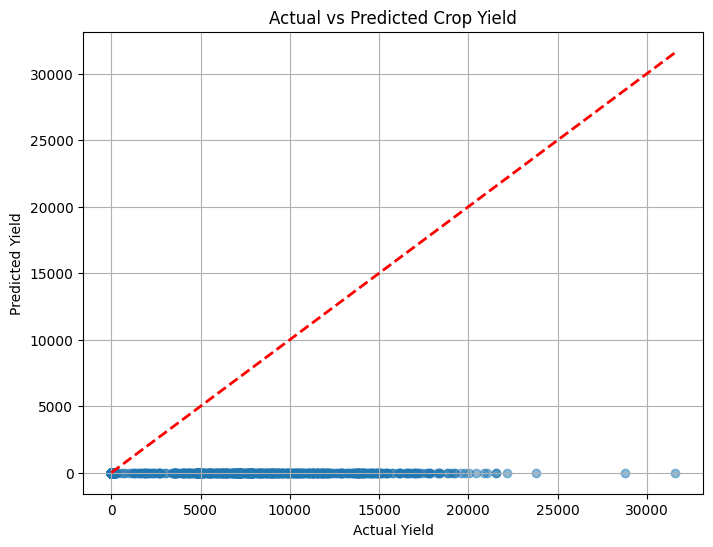

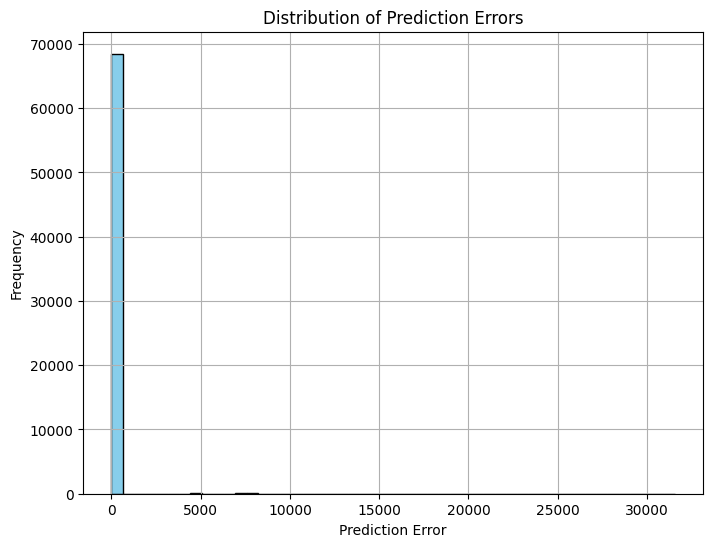

In [7]:
# ==========================================
# Script: Check Model Predictions (Direct from Training)
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1. Use existing X_test and y_test
# -----------------------------
# Make sure you have these variables from your training pipeline:
# X_test -> features of test set
# y_test -> actual yield values
# model -> your trained model

# -----------------------------
# 2. Make Predictions
# -----------------------------
y_pred = model.predict(X_test)

# -----------------------------
# 3. Compare Predictions with Actuals
# -----------------------------
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Error': y_test - y_pred
})

print("\n=== Sample Predictions ===")
print(comparison.head(10))

print("\n=== Prediction Error Statistics ===")
print(comparison['Error'].describe())

# -----------------------------
# 4. Visualizations
# -----------------------------
# Scatter Plot: Actual vs Predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield")
plt.grid(True)
plt.show()

# Histogram: Prediction Errors
plt.figure(figsize=(8,6))
plt.hist(comparison['Error'], bins=50, color='skyblue', edgecolor='black')
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(True)
plt.show()
